# Transfer Optimizer: who to move out and in

Combines **both forecasting models in the repo** and finds the best set of transfers for your current squad under the game's constraints.

- `ols_fantasy_model.ipynb` -> hybrid OLS forecasts (`data/squad_optimizer_input_hybrid.csv`)
- `rate_forecast_model.ipynb` -> component-rate forecasts converted to points (`out/rate_model_forecast_2627.csv`)
- Forecast combination (Forecasting course): equal-weight average of the available forecasts. Averaging forecasts with imperfectly correlated errors lowers error variance, and the rate model is the one with validated out-of-sample skill, so a weight sweep is shown below.

Constraints: budget, 2 GK / 5 DEF / 5 MID / 3 FWD, max 3 per club, and the transfer cost (free transfers, then -4 points for each extra).

In [1]:
import pandas as pd, numpy as np, pulp, matplotlib.pyplot as plt
pd.set_option('display.width', 200)
pool = pd.read_csv('data/uefa_fantasy_player_pool.csv')
ols  = pd.read_csv('data/squad_optimizer_input_hybrid.csv')[['Id','PredictedPts_BestK','Matched']]
rate = pd.read_csv('out/rate_model_forecast_2627.csv')[['Id','xpts','p_apps_share','p_mpa']].drop_duplicates('Id')
df = pool.merge(ols, on='Id', how='left').merge(rate, on='Id', how='left')
df['ols'] = np.where(df.Matched.fillna(False).astype(bool), df.PredictedPts_BestK, np.nan)
df['rate'] = df.xpts
print('OLS forecasts:', df.ols.notna().sum(), '| rate forecasts:', df.rate.notna().sum(), '| both:', (df.ols.notna() & df.rate.notna()).sum(), '| neither:', (df.ols.isna() & df.rate.isna()).sum())
print('correlation of the two models where both exist:', round(df[['ols','rate']].corr().iloc[0,1], 3))

OLS forecasts: 893 | rate forecasts: 572 | both: 549 | neither: 247
correlation of the two models where both exist: 0.621


## 1. Combine the forecasts
Weighted `W_RATE` on the rate model (default 0.5). A missing forecast is imputed with that position's mean for the same model, so one-model players are shrunk toward the middle.

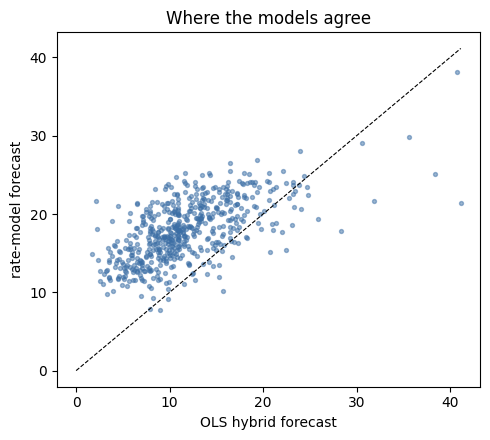

source
both         549
OLS only     344
rate only     23
Name: count, dtype: int64

In [2]:
W_RATE = 0.5
# A player with only ONE model's forecast is the classic winner's-curse pick (the optimizer loves the luckiest noisy number).
# So a missing forecast is replaced by that position's mean for the same model, which shrinks one-model players toward the middle.
def combine(w):
    ols_f = df.ols.fillna(df.groupby('Position').ols.transform('mean')); rate_f = df.rate.fillna(df.groupby('Position').rate.transform('mean'))
    return w*rate_f + (1-w)*ols_f
df['pred'] = combine(W_RATE)
df['source'] = np.select([df.ols.notna() & df.rate.notna(), df.rate.notna(), df.ols.notna()], ['both','rate only','OLS only'], 'none')
df = df[df.source != 'none'].copy()
fig, ax = plt.subplots(figsize=(5,4.5)); b = df[df.source=='both']
ax.scatter(b.ols, b.rate, s=8, alpha=.5, color='#3b6ea5'); m = max(b.ols.max(), b.rate.max()); ax.plot([0,m],[0,m],'k--',lw=.8)
ax.set_xlabel('OLS hybrid forecast'); ax.set_ylabel('rate-model forecast'); ax.set_title('Where the models agree'); plt.tight_layout(); plt.show()
df.source.value_counts()

## 2. Your current squad: what each model thinks of each player
Every number below is a **forecast of the player's total UCL fantasy points over the 8 league-phase games**. Two independent models each produce one:

| column | meaning |
|---|---|
| `Price` | what the player costs in your budget (EUR m) |
| `ols` | forecast from the OLS model (`ols_fantasy_model.ipynb`), built from domestic season totals |
| `rate` | forecast from the rate model (`rate_forecast_model.ipynb`): goals/90, assists/90, minutes etc., turned into points |
| `pred` | the **combined** forecast = average of the two (this is what the optimizer uses). If a model has no forecast (`NaN`), that model is replaced by its average for the position, so a single optimistic number can't dominate |

The chart shows the same thing visually: where the two bars (OLS, rate) are far apart the models disagree, and the black marker is the combined number used.

removed 179 unavailable players from the candidate pool
removed 508 non-regulars (availability < 65% of club games, < 60 min/appearance, or no playing-time projection); 229 candidates left
your squad with a fitness flag: [['Nuno Mendes', 'I'], ['M. Neuer', 'D']] (I = injured, D = doubtful)
squad players without any forecast: set()
squad cost 99.5m | combined forecast points 284.2


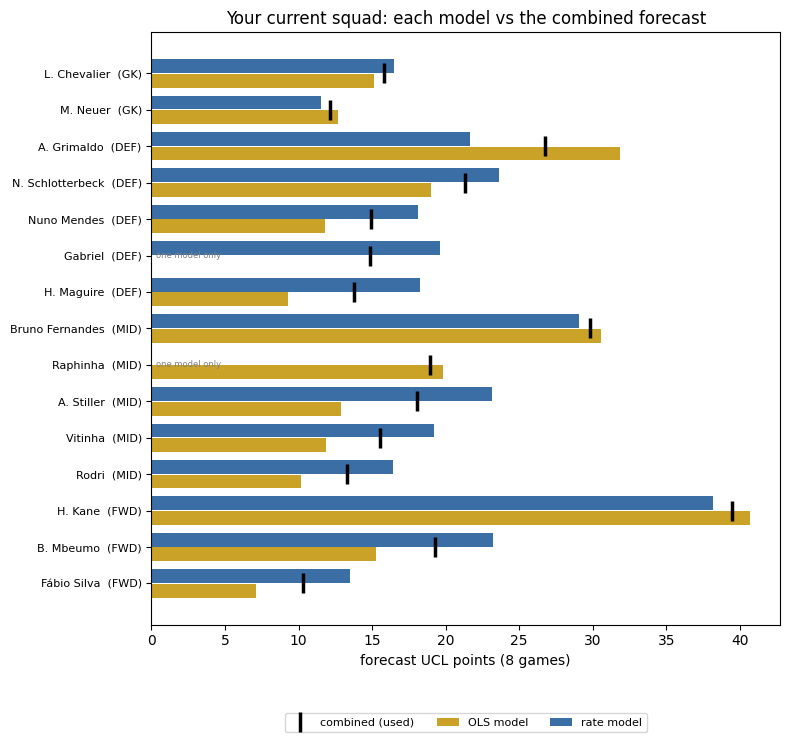

,Position,Name,Price,ols,rate,pred
0,DEF,H. Maguire,5.0,9.3,18.3,13.8
1,DEF,Gabriel,6.0,NaN,19.6,14.8
2,DEF,Nuno Mendes,6.0,11.8,18.1,14.9
3,DEF,N. Schlotterbeck,5.0,19.0,23.7,21.3
4,DEF,A. Grimaldo,5.5,31.8,21.7,26.8
5,FWD,Fábio Silva,5.5,7.1,13.5,10.3
6,FWD,B. Mbeumo,7.0,15.3,23.2,19.3
7,FWD,H. Kane,11.0,40.7,38.2,39.4
8,GK,M. Neuer,5.5,12.7,11.5,12.1
9,GK,L. Chevalier,4.5,15.1,16.5,15.8


In [3]:
MY_SQUAD = {250131901, 250042422, 250112880, 250016833, 97923, 250113350, 250134856,
            250078886, 250075007, 250137260, 250082664, 250135068, 250136465, 250101444, 250112217}
# Availability (live UEFA feed): drop injured (I), suspended (S) and not-in-squad (NIS) players as transfer TARGETS. Doubtful (D) stay but are flagged.
# Your own players are always kept in the data so they can be valued/sold.
n_before = len(df); df = df[~df.Status.isin(['I', 'S', 'NIS']) | df.Id.isin(MY_SQUAD)].copy()
print(f'removed {n_before - len(df)} unavailable players from the candidate pool')
# Regular starters only: transfer targets must be projected to play most club games and long minutes (rate model: availability share and
# minutes per appearance, based on a full domestic season, not one matchday). Players with no such projection cannot be verified, so they are excluded too.
MIN_SHARE, MIN_MPA = 0.65, 60
n_before = len(df); regular = (df.p_apps_share >= MIN_SHARE) & (df.p_mpa >= MIN_MPA)
df = df[regular | df.Id.isin(MY_SQUAD)].copy()
print(f'removed {n_before - len(df)} non-regulars (availability < {MIN_SHARE:.0%} of club games, < {MIN_MPA} min/appearance, or no playing-time projection); {len(df)} candidates left')
mine = df[df.Id.isin(MY_SQUAD)].copy()
print('your squad with a fitness flag:', mine[mine.Status.notna()][['Name', 'Status']].values.tolist(), '(I = injured, D = doubtful)')
missing = MY_SQUAD - set(mine.Id); print('squad players without any forecast:', missing)
print(f"squad cost {mine.Price.sum():.1f}m | combined forecast points {mine.pred.sum():.1f}")

def model_chart(players, title, ax=None):
    pl = players.assign(pos_o=players.Position.map({'GK':0,'DEF':1,'MID':2,'FWD':3})).sort_values(['pos_o','pred'], ascending=[False, True])
    y = np.arange(len(pl)); ax = ax or plt.subplots(figsize=(8, 0.42*len(pl)+1.2))[1]
    ax.barh(y-.2, pl.ols.fillna(0), .38, color='#c9a227', label='OLS model')
    ax.barh(y+.2, pl.rate.fillna(0), .38, color='#3b6ea5', label='rate model')
    ax.plot(pl.pred, y, 'k|', ms=14, mew=2.5, label='combined (used)')
    ax.set_yticks(y); ax.set_yticklabels([f"{n}  ({p})" for n, p in zip(pl.Name, pl.Position)], fontsize=8)
    ax.set_xlabel('forecast UCL points (8 games)'); ax.set_title(title); ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3)
    for yi, (o, r) in enumerate(zip(pl.ols, pl.rate)):
        if np.isnan(o) or np.isnan(r): ax.text(0.3, yi, 'one model only', fontsize=6, va='center', color='gray')
model_chart(mine, 'Your current squad: each model vs the combined forecast'); plt.tight_layout(); plt.show()
mine.sort_values(['Position','pred'])[['Position','Name','Price','ols','rate','pred']].round(1).reset_index(drop=True)

## 3. How the transfers are chosen (step by step)
**The question:** which players should leave your squad and which should come in so that your projected points go up the most?

**What the optimizer does, in plain words**
1. Every player in the game gets a yes/no switch: "is he in my squad after the transfers?"
2. It tries to maximise `total combined forecast of the 15 chosen players - 4 x (transfers beyond the free ones)`.
3. It may only pick squads that obey the rules: total price within the budget, exactly 2 GK / 5 DEF / 5 MID / 3 FWD, max 3 per club.
4. A "transfer" is any player in the new 15 who is not in your current 15. The first `FREE` (3) are free; each extra costs 4 points.
5. Because transfers cost points, we ask the question several times: *"what is the best squad if I may make at most 0, 1, 2, ... transfers?"* The table shows the answer for each, so you can see what every extra transfer buys.

**Reading the table:** `max_transfers` = the limit we gave it, `transfers_used` = how many it actually made, `gross_pts` = projected points of the new squad before the penalty, `net_pts` = after the -4 penalties (the number to compare), `cost` = squad price.
Row 0 is "do nothing" (your **before** number); every other row is an **after** number.

,max_transfers,transfers_used,gross_pts,net_pts,cost
0,0,0,284.2,284.2,99.5
1,1,1,296.1,296.1,98.5
2,2,2,308.5,308.5,100.0
3,3,3,321.9,321.9,100.0
4,4,4,334.0,330.0,100.0
5,5,5,344.8,336.8,100.0
6,6,6,354.6,342.6,100.0
7,7,7,361.9,345.9,100.0
8,8,8,370.9,350.9,100.0
9,9,9,377.9,353.9,100.0


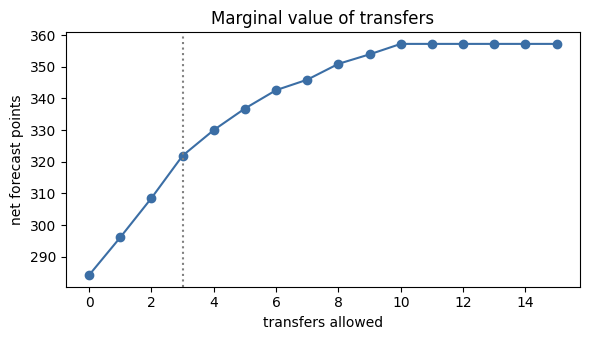

In [4]:
FREE, PENALTY, BANK = 3, 4, 0.5
BUDGET = mine.Price.sum() + BANK
QUOTA = {'GK':2,'DEF':5,'MID':5,'FWD':3}; MAX_CLUB = 3
def solve(max_tr):
    p = pulp.LpProblem('t', pulp.LpMaximize); x = {r.Id: pulp.LpVariable(f'x{r.Id}', cat='Binary') for r in df.itertuples()}
    ex = pulp.LpVariable('extra', lowBound=0)
    kept = pulp.lpSum(x[i] for i in x if i in MY_SQUAD); tr = 15 - kept
    p += pulp.lpSum(x[r.Id]*r.pred for r in df.itertuples()) - PENALTY*ex
    p += ex >= tr - FREE
    p += tr <= max_tr
    p += pulp.lpSum(x[r.Id]*r.Price for r in df.itertuples()) <= BUDGET
    for pos, q in QUOTA.items(): p += pulp.lpSum(x[r.Id] for r in df.itertuples() if r.Position == pos) == q
    for c in df.Team.unique(): p += pulp.lpSum(x[r.Id] for r in df.itertuples() if r.Team == c) <= MAX_CLUB
    p.solve(pulp.PULP_CBC_CMD(msg=0))
    ids = [i for i, v in x.items() if v.value() > .5]; s = df[df.Id.isin(ids)]
    n = len(set(ids) - MY_SQUAD)
    return s, n, s.pred.sum() - PENALTY*max(0, n-FREE)
rows = []; sols = {}
for k in range(0, 16):
    s, n, net = solve(k); sols[k] = s; rows.append(dict(max_transfers=k, transfers_used=n, gross_pts=s.pred.sum(), net_pts=net, cost=s.Price.sum()))
sweep = pd.DataFrame(rows).round(1); display(sweep)
fig, ax = plt.subplots(figsize=(6,3.5)); ax.plot(sweep.max_transfers, sweep.net_pts, 'o-', color='#3b6ea5'); ax.axvline(FREE, color='gray', ls=':')
ax.set_xlabel('transfers allowed'); ax.set_ylabel('net forecast points'); ax.set_title('Marginal value of transfers'); plt.tight_layout(); plt.show()

## Is 11 transfers really the best move? (a reality check)
The optimiser only sees the forecast **averages**, and it keeps spending transfers as long as each one adds even a little. That is right if the forecasts were exact, but they are not:
on the 2024 and 2025 seasons the rate model's season-total forecast was off by about **15-19 points per player** (residual standard deviation), which is as large as the gain from many individual swaps.
So three questions are worth asking before trusting a many-transfer plan:

1. **Marginal value:** how much does the 3rd, 4th, ... transfer add? (diminishing returns)
2. **Risk:** if we replay the season many times with realistic forecast errors, how often does the plan actually beat doing nothing?
3. **Stability:** do the same players get picked no matter how the two models are weighted? A swap that only appears under one weighting is probably chasing noise.

,marginal_net,expected_gain,prob_beats_no_change,bad_case_10pct,sd
max_transfers,,,,,
1,11.9,11.49,0.71,-15.35,21.11
2,12.4,24.68,0.78,-18.03,32.96
3,13.4,38.55,0.84,-10.30,38.38
4,8.1,46.81,0.85,-12.09,46.29
5,6.8,52.53,0.84,-12.76,51.18
6,5.8,57.98,0.84,-14.79,57.27
7,3.3,62.11,0.84,-18.55,61.58
8,5.0,66.26,0.85,-16.68,64.97
9,3.0,69.70,0.84,-19.98,69.73


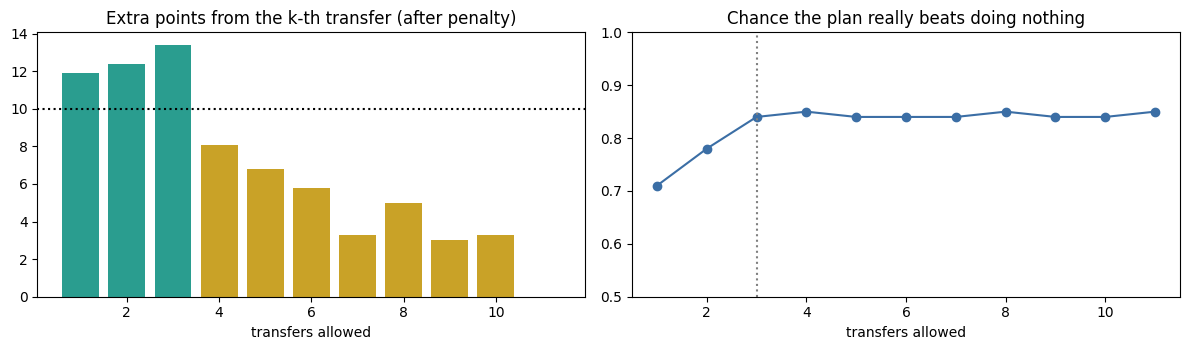

In [5]:
sweep['marginal_net'] = sweep.net_pts.diff()            # what the k-th allowed transfer adds after penalties
SD = {'GK': 14.9, 'DEF': 16.6, 'MID': 14.5, 'FWD': 18.6}  # residual SD of forecast vs official points, 2024-25 validation
rng = np.random.default_rng(0); N = 4000
def mc(k):
    new_k = sols[k]; drop = mine[~mine.Id.isin(new_k.Id)]; add = new_k[~new_k.Id.isin(MY_SQUAD)]
    n = len(add); pen = PENALTY * max(0, n - FREE)
    noise = lambda d: rng.normal(0, d.Position.map(SD).values, (N, len(d))).sum(axis=1) if len(d) else np.zeros(N)
    g = (add.pred.sum() + noise(add)) - (drop.pred.sum() + noise(drop)) - pen
    return pd.Series({'expected_gain': g.mean(), 'prob_beats_no_change': (g > 0).mean(), 'bad_case_10pct': np.percentile(g, 10), 'sd': g.std()})
risk = pd.DataFrame({k: mc(k) for k in range(1, 12)}).T.round(2); risk.index.name = 'max_transfers'
display(pd.concat([sweep.set_index('max_transfers')[['marginal_net']].round(1), risk], axis=1).loc[1:11])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(sweep.max_transfers[1:12], sweep.marginal_net[1:12], color=['#2a9d8f' if v >= 10 else '#c9a227' for v in sweep.marginal_net[1:12]]); ax[0].axhline(10, color='k', ls=':')
ax[0].set_title('Extra points from the k-th transfer (after penalty)'); ax[0].set_xlabel('transfers allowed')
ax[1].plot(risk.index, risk.prob_beats_no_change, 'o-', color='#3b6ea5', label='P(beats no change)'); ax[1].plot(risk.index, risk.bad_case_10pct/ risk.bad_case_10pct.abs().max() + .5, alpha=0)
ax[1].set_ylim(.5, 1); ax[1].set_title('Chance the plan really beats doing nothing'); ax[1].set_xlabel('transfers allowed'); ax[1].axvline(FREE, color='gray', ls=':')
plt.tight_layout(); plt.show()

**How to read it.** `marginal_net` is the extra projected points from allowing one more transfer. The first two are free and add the most; after that every extra transfer costs 4 points and the gain per transfer shrinks, soon to the same size as the forecast noise.
`prob_beats_no_change` is simulated with *independent* player errors, so it is flattering for large plans: it ignores risks the model cannot see (rotation, injuries, a new coach, the OLS model being less reliable than the rate model, and fewer games left). That is why a **minimum marginal gain** rule is used to pick the plan instead of taking the raw maximum.

In [6]:
from collections import Counter
cnt = Counter(); mixes = [0, .25, .5, .75, 1]; keep_pred = df.pred.copy()
for w in mixes:
    df['pred'] = combine(w); s_, n_, _ = solve(6); cnt.update(s_[~s_.Id.isin(MY_SQUAD)].Id)
    cnt_out = None
df['pred'] = keep_pred
stab = df[df.Id.isin(cnt)].assign(times_picked=lambda d: d.Id.map(cnt))[['Position','Name','Price','pred','times_picked']].sort_values('times_picked', ascending=False)
print('How often each incoming player is picked across the 5 model weightings (out of 5), using up to 6 transfers:')
stab.round(1).reset_index(drop=True)

How often each incoming player is picked across the 5 model weightings (out of 5), using up to 6 transfers:


,Position,Name,Price,pred,times_picked
0,MID,I. Saibari,6.5,23.8,5
1,DEF,F. Dimarco,5.0,24.6,4
2,GK,J. Butez,4.5,24.1,4
3,DEF,B. Mechele,4.5,22.3,3
4,FWD,K. Mbappé,11.0,31.8,2
5,FWD,E. Haaland,11.0,32.7,2
6,DEF,N. Brown,4.0,22.1,2
7,DEF,Gonçalo Inácio,4.5,21.5,2
8,FWD,L. Suárez,7.0,20.9,1
9,MID,T. Hazard,5.5,22.3,1


In [7]:
MIN_MARGINAL = 10   # a transfer beyond the free ones must add at least this many projected points (after its -4 penalty)
raw_best = int(sweep.loc[sweep.net_pts.idxmax(), 'max_transfers'])
best_k = 0
for k in range(1, 16):
    if sweep.marginal_net[k] >= MIN_MARGINAL: best_k = k
    else: break
new = sols[best_k]
print(f'raw maximum would be {raw_best} transfers; the minimum-marginal-gain rule (>= {MIN_MARGINAL} pts each) stops at {best_k}')
out_ = mine[~mine.Id.isin(new.Id)].sort_values('Position'); in_ = new[~new.Id.isin(MY_SQUAD)].sort_values('Position')
print(f'Best plan: {len(in_)} transfers, net {sweep.net_pts[best_k]:.1f} pts vs {sweep.net_pts.iloc[0]:.1f} keeping the squad')

raw maximum would be 10 transfers; the minimum-marginal-gain rule (>= 10 pts each) stops at 3
Best plan: 3 transfers, net 321.9 pts vs 284.2 keeping the squad


### What 'transfer out / transfer in' means here
Players are swapped **within the same position** (a defender out means a defender in), because the squad must stay 2/5/5/3. The table pairs each outgoing player with an incoming one of the same position and shows the change in price and projected points. A player is sent out when (a) his combined forecast is low for his price, or (b) selling him frees budget that buys a bigger forecast elsewhere.

In [8]:
def swap_table(o, i):
    rows = []
    for pos in ['GK','DEF','MID','FWD']:
        oo = o[o.Position==pos].sort_values('pred'); ii = i[i.Position==pos].sort_values('pred')
        for a, b in zip(oo.itertuples(), ii.itertuples()):
            rows.append({'pos':pos,'OUT':a.Name,'out price':a.Price,'out pts':a.pred,'IN':b.Name,'in price':b.Price,'in pts':b.pred,
                         'price change':b.Price-a.Price,'points change':b.pred-a.pred})
    return pd.DataFrame(rows)
sw = swap_table(out_, in_); display(sw.round(1))
print(f"total points change {sw['points change'].sum():+.1f} | price change {sw['price change'].sum():+.1f}m")

,pos,OUT,out price,out pts,IN,in price,in pts,price change,points change
0,GK,M. Neuer,5.5,12.1,J. Butez,4.5,24.1,-1.0,12.0
1,MID,Raphinha,9.5,18.9,T. Hazard,5.5,22.3,-4.0,3.4
2,FWD,Fábio Silva,5.5,10.3,E. Haaland,11.0,32.7,5.5,22.4


total points change +37.8 | price change +0.5m


### Before vs after: projected points

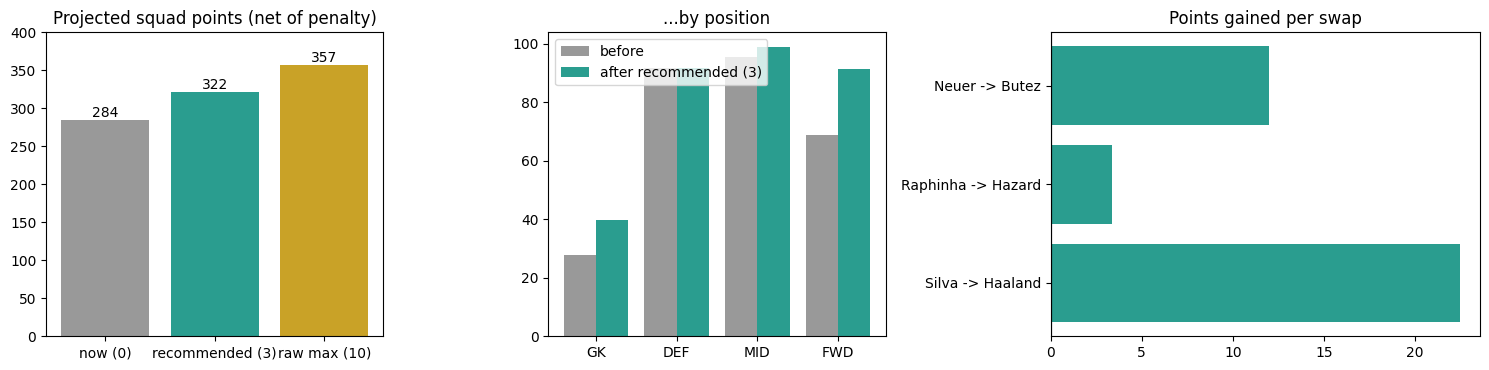

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios':[1.1,1.1,1.4]})
labs = ['now (0)', f'recommended ({best_k})', f'raw max ({raw_best})']; vals = [sweep.net_pts[0], sweep.net_pts[best_k], sweep.net_pts[raw_best]]
bars = ax[0].bar(labs, vals, color=['#999','#2a9d8f','#c9a227']); ax[0].bar_label(bars, fmt='%.0f'); ax[0].set_ylim(0, max(vals)*1.12)
ax[0].set_title('Projected squad points (net of penalty)')
bp = mine.groupby('Position').pred.sum().reindex(['GK','DEF','MID','FWD']); ap = new.groupby('Position').pred.sum().reindex(['GK','DEF','MID','FWD'])
xx = np.arange(4); ax[1].bar(xx-.2, bp, .4, color='#999', label='before'); ax[1].bar(xx+.2, ap, .4, color='#2a9d8f', label=f'after recommended ({best_k})')
ax[1].set_xticks(xx); ax[1].set_xticklabels(bp.index); ax[1].legend(); ax[1].set_title('...by position')
lab = [f"{r.OUT.split()[-1]} -> {r.IN.split()[-1]}" for r in sw.itertuples()]
ax[2].barh(lab[::-1], sw['points change'][::-1], color=['#2a9d8f' if v>0 else '#c0392b' for v in sw['points change'][::-1]])
ax[2].set_title('Points gained per swap'); ax[2].axvline(0, color='k', lw=.8)
plt.tight_layout(); plt.show()

### The individuals involved: both models, for every player going out and coming in

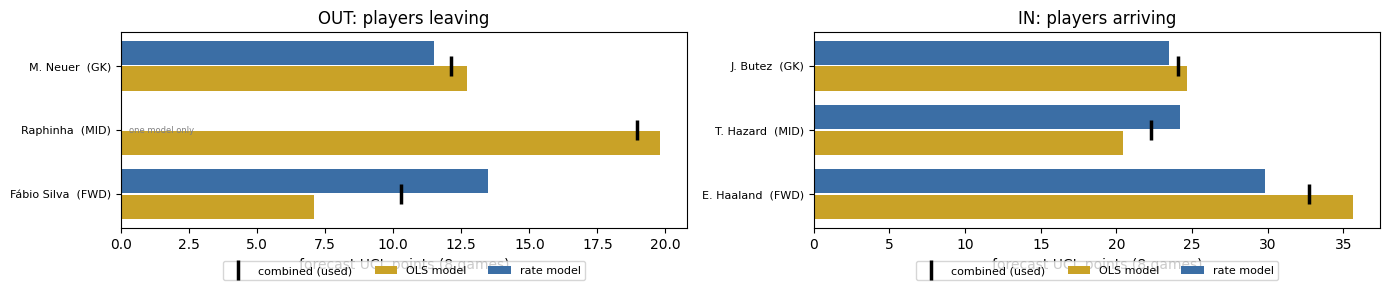

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 0.42*max(len(out_), len(in_))+1.8))
model_chart(out_, 'OUT: players leaving', ax[0]); model_chart(in_, 'IN: players arriving', ax[1]); plt.tight_layout(); plt.show()

### The free-transfer plan (no points penalty)
The unconstrained optimum above uses many transfers and leans on forecasts for the whole season; the plan below uses only the free transfers.

3 free transfers: +37.8 forecast pts, cost 100.0m
OUT: Raphinha (MID, 18.9), Fábio Silva (FWD, 10.3), M. Neuer (GK, 12.1)
IN:  E. Haaland (FWD, €11.0m, 32.7), T. Hazard (MID, €5.5m, 22.3), J. Butez (GK, €4.5m, 24.1)


,pos,OUT,out price,out pts,IN,in price,in pts,price change,points change
0,GK,M. Neuer,5.5,12.1,J. Butez,4.5,24.1,-1.0,12.0
1,MID,Raphinha,9.5,18.9,T. Hazard,5.5,22.3,-4.0,3.4
2,FWD,Fábio Silva,5.5,10.3,E. Haaland,11.0,32.7,5.5,22.4


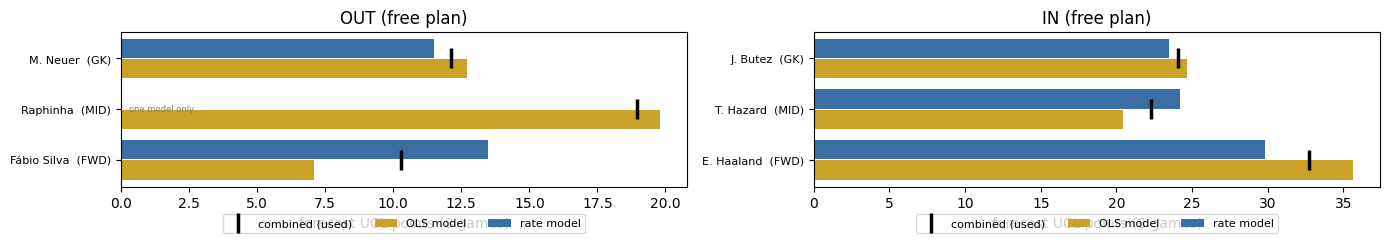

In [11]:
fs = sols[FREE]; o2 = mine[~mine.Id.isin(fs.Id)]; i2 = fs[~fs.Id.isin(MY_SQUAD)]
print(f'{FREE} free transfers: +{fs.pred.sum()-mine.pred.sum():.1f} forecast pts, cost {fs.Price.sum():.1f}m')
print('OUT:', ', '.join(f'{r.Name} ({r.Position}, {r.pred:.1f})' for r in o2.itertuples()))
print('IN: ', ', '.join(f'{r.Name} ({r.Position}, €{r.Price}m, {r.pred:.1f})' for r in i2.itertuples()))
display(swap_table(o2, i2).round(1))
fig, ax = plt.subplots(1, 2, figsize=(14, 2.6)); model_chart(o2, 'OUT (free plan)', ax[0]); model_chart(i2, 'IN (free plan)', ax[1]); plt.tight_layout(); plt.show()

## Your own plan: Rodri, Maguire and Fabio Silva out; maybe Bruno Fernandes / Mbeumo / Chevalier
Instead of letting the optimiser choose who leaves, **you** choose the sellers and it finds the best replacements.
- `MUST_OUT`: sold for sure. `MAYBE_OUT`: the optimiser tests every combination of selling or keeping them, so you can see what each extra sale is worth.
- Everyone else in your squad is kept. Replacements must be the same position, fit the budget and the 3-per-club limit.

In [12]:
import itertools
MUST_OUT = ['Rodri', 'H. Maguire', 'Fábio Silva']
MAYBE_OUT = ['Bruno Fernandes', 'B. Mbeumo', 'L. Chevalier']
id_of = lambda n: int(mine.loc[mine.Name == n, 'Id'].iloc[0])
must = {id_of(n) for n in MUST_OUT}; maybe = {n: id_of(n) for n in MAYBE_OUT}

def solve_fixed(sell):
    keep = MY_SQUAD - sell
    p = pulp.LpProblem('t', pulp.LpMaximize); x = {r.Id: pulp.LpVariable(f'x{r.Id}', cat='Binary') for r in df.itertuples()}
    p += pulp.lpSum(x[r.Id]*r.pred for r in df.itertuples())
    p += pulp.lpSum(x[r.Id]*r.Price for r in df.itertuples()) <= BUDGET
    for i in keep: p += x[i] == 1
    for i in sell: p += x[i] == 0
    for pos, q in QUOTA.items(): p += pulp.lpSum(x[r.Id] for r in df.itertuples() if r.Position == pos) == q
    for c in df.Team.unique(): p += pulp.lpSum(x[r.Id] for r in df.itertuples() if r.Team == c) <= MAX_CLUB
    p.solve(pulp.PULP_CBC_CMD(msg=0))
    if pulp.LpStatus[p.status] != 'Optimal': return None
    ids = [i for i, v in x.items() if v.value() > .5]; return df[df.Id.isin(ids)]

rows, plans = [], {}
for r_ in range(len(maybe) + 1):
    for combo in itertools.combinations(maybe, r_):
        sell = must | {maybe[n] for n in combo}; sq = solve_fixed(sell)
        if sq is None: continue
        n_tr = len(sell); net = sq.pred.sum() - PENALTY * max(0, n_tr - FREE)
        key = ' + '.join(['3 must'] + list(combo)); plans[key] = (sell, sq)
        rows.append({'plan': key, 'transfers': n_tr, 'gross_pts': sq.pred.sum(), 'penalty': PENALTY*max(0, n_tr-FREE), 'net_pts': net, 'gain_vs_now': net - mine.pred.sum(), 'cost': sq.Price.sum()})
mine_plans = pd.DataFrame(rows).round(1); display(mine_plans)

,plan,transfers,gross_pts,penalty,net_pts,gain_vs_now,cost
0,3 must,3,315.4,0,315.4,31.3,100.0
1,3 must + Bruno Fernandes,4,319.0,4,315.0,30.8,100.0
2,3 must + B. Mbeumo,4,321.5,4,317.5,33.3,100.0
3,3 must + L. Chevalier,4,323.7,4,319.7,35.5,100.0
4,3 must + Bruno Fernandes + B. Mbeumo,5,321.3,8,313.3,29.2,100.0
5,3 must + Bruno Fernandes + L. Chevalier,5,327.3,8,319.3,35.1,100.0
6,3 must + B. Mbeumo + L. Chevalier,5,329.8,8,321.8,37.6,100.0
7,3 must + Bruno Fernandes + B. Mbeumo + L. Chev...,6,329.6,12,317.6,33.4,100.0


Best of your plans: 3 must + B. Mbeumo + L. Chevalier


,pos,OUT,out price,out pts,IN,in price,in pts,price change,points change
0,GK,L. Chevalier,4.5,15.8,J. Butez,4.5,24.1,0.0,8.3
1,DEF,H. Maguire,5.0,13.8,N. Brown,4.0,22.1,-1.0,8.3
2,MID,Rodri,7.0,13.3,P. Fornals,5.0,21.5,-2.0,8.2
3,FWD,Fábio Silva,5.5,10.3,Troy Parrott,5.0,17.6,-0.5,7.4
4,FWD,B. Mbeumo,7.0,19.3,E. Haaland,11.0,32.7,4.0,13.5


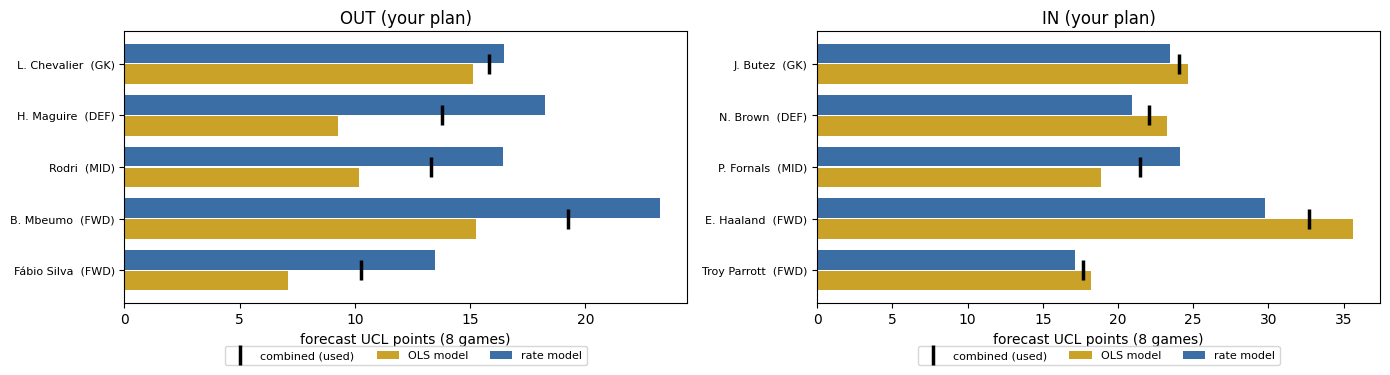

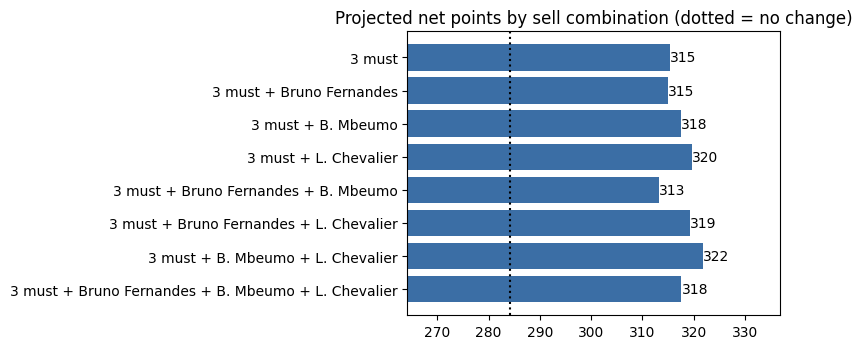

In [13]:
best_key = mine_plans.loc[mine_plans.net_pts.idxmax(), 'plan']; sell, sq = plans[best_key]
o3 = mine[mine.Id.isin(sell)]; i3 = sq[~sq.Id.isin(MY_SQUAD)]
print('Best of your plans:', best_key)
display(swap_table(o3, i3).round(1))
fig, ax = plt.subplots(1, 2, figsize=(14, 0.42*max(len(o3), len(i3))+1.8)); model_chart(o3, 'OUT (your plan)', ax[0]); model_chart(i3, 'IN (your plan)', ax[1]); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 3.6)); b = ax.barh(mine_plans.plan[::-1], mine_plans.net_pts[::-1], color='#3b6ea5'); ax.bar_label(b, fmt='%.0f')
ax.axvline(mine.pred.sum(), color='k', ls=':'); ax.set_xlim(mine.pred.sum()-20, mine_plans.net_pts.max()+15); ax.set_title('Projected net points by sell combination (dotted = no change)'); plt.tight_layout(); plt.show()

**How to read it.** Each row sells the three must-sells plus a subset of the maybes. `gain_vs_now` is the projected change in squad points after the -4 penalty for any transfer beyond your 3 free ones.
If adding Bruno, Mbeumo or Chevalier to the sell list lifts `net_pts` by less than about 10, selling him is not clearly worth it given the forecast noise. Those are the candidates to keep.

## 4. Sanity checks and sensitivity

In [14]:
assert len(new) == 15 and new.Price.sum() <= BUDGET + 1e-6 and (new.Team.value_counts() <= MAX_CLUB).all()
for pos, q in QUOTA.items(): assert (new.Position == pos).sum() == q
print('constraints hold | spent', new.Price.sum(), 'of', round(BUDGET,1))
res = []
for w in [0, .25, .5, .75, 1]:
    df['pred'] = combine(w)
    s, n, net = solve(6); res.append(dict(W_RATE=w, transfers=n, net_pts=round(net,1), players_in=', '.join(s[~s.Id.isin(MY_SQUAD)].Name)))
pd.DataFrame(res)

constraints hold | spent 100.0 of 100.0


,W_RATE,transfers,net_pts,players_in
0,0.00,6,342.0,"K. Mbappé, I. Saibari, F. Dimarco, B. Mechele,..."
1,0.25,6,342.3,"K. Mbappé, I. Saibari, F. Dimarco, B. Mechele,..."
2,0.50,6,344.4,"E. Haaland, I. Saibari, T. Hazard, F. Dimarco,..."
3,0.75,6,350.7,"E. Haaland, I. Saibari, G. Til, F. Dimarco, J...."
4,1.00,6,362.0,"L. Suárez, I. Saibari, J. Bednarek, Gonçalo In..."


**Caveats.** Forecasts are season totals for 8 league-phase games, so they say who to *hold for the season*, not who has the best next fixture. The pool is a snapshot of prices; the transfer penalty compares season-long gains with a one-off -4,
so for late transfers the remaining-games horizon is shorter than assumed. Players with neither forecast are excluded as targets. Injuries, rotation and fixtures are not modelled.